In [1]:
import ee
ee.Initialize(project="tree-fire-510209")

sierra_bbox = ee.Geometry.Rectangle([-119.5, 35.5, -118.5, 37.5])
gfc = ee.Image("UMD/hansen/global_forest_change_2023_v1_11")

loss_year = gfc.select("lossyear").clip(sierra_bbox)  # 0 = no loss; else 2000+value = year

url = loss_year.getDownloadURL({
    "scale": 100,
    "region": sierra_bbox,
    "format": "GEO_TIFF",
})
print(url)


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for UMD/hansen/global_forest_change_2023_v1_11! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by UMD/hansen/global_forest_change_2025_v1_13

Learn more: https://developers.google.com/earth-engine/datasets/catalog/UMD_hansen_global_forest_change_2023_v1_11

  warnings.warn(warning, category=DeprecationWarning)


https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/4dc131b2f7d3d668975fb91035f16b01-4315f5ad6bdec958c394de1e076e4a20:getPixels


disturbed fraction of bbox: 0.06220515757281405


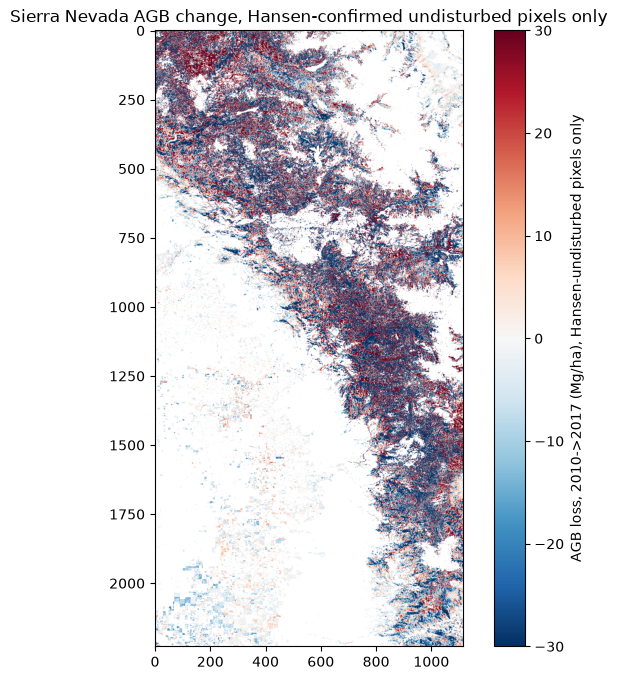

In [4]:
import rasterio
import numpy as np

with rasterio.open("../data/raw/hansen_lossyear.tif") as src:
    lossyear = src.read(1)  # 0 = no loss detected 2001-2023

# any detected loss 2010-2018 (encoded as 10-18)
disturbed_mask = (lossyear >= 10) & (lossyear <= 18)
print("disturbed fraction of bbox:", disturbed_mask.mean())

with rasterio.open("../data/raw/agb/agb_2010.tif") as src:
    agb_2010 = src.read(1, masked=True).astype("float32").filled(np.nan)
with rasterio.open("../data/raw/agb/agb_2017.tif") as src:
    agb_2017 = src.read(1, masked=True).astype("float32").filled(np.nan)

loss = agb_2010 - agb_2017
loss_undisturbed = np.where(disturbed_mask, np.nan, loss)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(loss_undisturbed, cmap="RdBu_r", vmin=-30, vmax=30)
plt.colorbar(im, label="AGB loss, 2010->2017 (Mg/ha), Hansen-undisturbed pixels only")
plt.title("Sierra Nevada AGB change, Hansen-confirmed undisturbed pixels only")
plt.savefig("../data/raw/agb_loss_map_undisturbed.png", dpi=150)
plt.show()


In [5]:
import ee
ee.Initialize(project="tree-fire-510209")

sierra_bbox = ee.Geometry.Rectangle([-119.5, 35.5, -118.5, 37.5])
agb_diff = ee.ImageCollection("projects/sat-io/open-datasets/ESA/ESA_CCI_AGB_DIFF")
print(agb_diff.aggregate_array("system:index").getInfo())  # confirm which year-pairs actually exist


['CCI_BIOMASS_DIFF_AGB_100m_2010_2007', 'CCI_BIOMASS_DIFF_AGB_100m_2016_2015', 'CCI_BIOMASS_DIFF_AGB_100m_2017_2016', 'CCI_BIOMASS_DIFF_AGB_100m_2018_2017', 'CCI_BIOMASS_DIFF_AGB_100m_2019_2018', 'CCI_BIOMASS_DIFF_AGB_100m_2020_2010', 'CCI_BIOMASS_DIFF_AGB_100m_2020_2019', 'CCI_BIOMASS_DIFF_AGB_100m_2021_2020', 'CCI_BIOMASS_DIFF_AGB_100m_2022_2021']


In [6]:
import ee
ee.Initialize(project="tree-fire-510209")

sierra_bbox = ee.Geometry.Rectangle([-119.5, 35.5, -118.5, 37.5])

# 2020 AGB mosaic
agb = ee.ImageCollection("ESA/CCI/Above_Ground_Biomass/V6_0")
img_2020 = agb.filter(ee.Filter.eq("system:index", "2020")).first().clip(sierra_bbox)
url_2020 = img_2020.getDownloadURL({"scale": 100, "region": sierra_bbox, "format": "GEO_TIFF"})
print("2020 AGB:", url_2020)

# official diff product's SD + QF bands
agb_diff = ee.ImageCollection("projects/sat-io/open-datasets/ESA/ESA_CCI_AGB_DIFF")
diff_2020_2010 = agb_diff.filter(ee.Filter.eq("system:index", "CCI_BIOMASS_DIFF_AGB_100m_2020_2010")).first()
print("diff bands:", diff_2020_2010.bandNames().getInfo())
diff_clip = diff_2020_2010.clip(sierra_bbox)
url_diff = diff_clip.getDownloadURL({"scale": 100, "region": sierra_bbox, "format": "GEO_TIFF"})
print("diff SD/QF:", url_diff)


2020 AGB: https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/ddc2258375bae6b959d45974782800ef-4eb1c429f771fa6fe22286053376b37e:getPixels
diff bands: ['AGB_DIFF_SD', 'AGB_DIFF_QF']
diff SD/QF: https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/8fc99d806b74f876a49f9575854c330e-fe592a01ad23c7810fd4f3cee16190b1:getPixels


In [8]:
with rasterio.open("../data/raw/agb_diff_2020_2010.tif") as src:
    print("bands:", src.count, src.descriptions)
    sd = src.read(1)
    qf = src.read(2)
    print("SD: min", sd.min(), "max", sd.max(), "mean", sd.mean())
    print("QF: unique values", np.unique(qf))


bands: 2 (None, None)
SD: min 0 max 325 mean 30.419327648517623
QF: unique values [0 1 2 3 4 5]


In [9]:
import ee
ee.Initialize(project="tree-fire-510209")

sierra_bbox = ee.Geometry.Rectangle([-119.5, 35.5, -118.5, 37.5])
agb_diff = ee.ImageCollection("projects/sat-io/open-datasets/ESA/ESA_CCI_AGB_DIFF")

steps = ["2016_2015", "2017_2016", "2018_2017", "2019_2018", "2020_2019"]
for step in steps:
    img = agb_diff.filter(ee.Filter.eq("system:index", f"CCI_BIOMASS_DIFF_AGB_100m_{step}")).first().clip(sierra_bbox)
    url = img.getDownloadURL({"scale": 100, "region": sierra_bbox, "format": "GEO_TIFF"})
    print(step, url)

# also need the 2019 mosaic, not yet pulled
agb = ee.ImageCollection("ESA/CCI/Above_Ground_Biomass/V6_0")
img_2019 = agb.filter(ee.Filter.eq("system:index", "2019")).first().clip(sierra_bbox)
url_2019 = img_2019.getDownloadURL({"scale": 100, "region": sierra_bbox, "format": "GEO_TIFF"})
print("2019 AGB:", url_2019)


2016_2015 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/53bf3579aa4f0e12d83d28d51d5903be-b7107c50c9f379e0efa9cf7c89afac91:getPixels
2017_2016 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/d11e00dd457ebbaacdf05d0ee2952553-34478300fede64e59d20dfe5c38c3263:getPixels
2018_2017 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/5afb9f498378283854d4843935bb97b0-186a4d861a47bccd50fe6c6f47c0dca8:getPixels
2019_2018 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/6323008fae744ec3e6dc525b31a54203-9f736dc9b4ade112db50a09300bc0d62:getPixels
2020_2019 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/38501b0f2974cc20aad7c01fdb58ac93-38dff1d7465a63c66eb79cf3e8969ff4:getPixels
2019 AGB: https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/6296f42ee3a5938130ec27b319c81f4e-6e348006b11323b594f19bc8078f085a:getPixels


fraction of bbox flagged 'improbable change' at least once across 2015-2020: 0.538096641867081


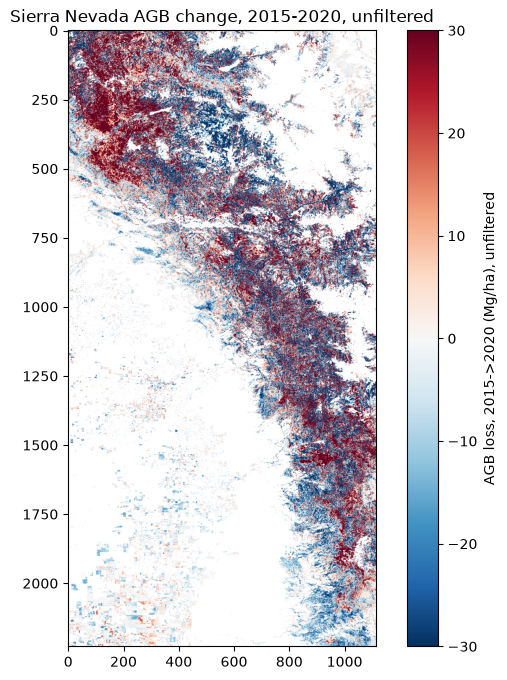

In [12]:
import rasterio
import numpy as np

steps = ["2016_2015", "2017_2016", "2018_2017", "2019_2018", "2020_2019"]
qf_unreliable_any_step = None

for step in steps:
    with rasterio.open(f"../data/raw/agb_diff_{step}.tif") as src:
        qf = src.read(2)
        flag = (qf == 3)  # "improbable change"
        qf_unreliable_any_step = flag if qf_unreliable_any_step is None else (qf_unreliable_any_step | flag)

print("fraction of bbox flagged 'improbable change' at least once across 2015-2020:", qf_unreliable_any_step.mean())

with rasterio.open("../data/raw/agb/agb_2015.tif") as src:
    agb_2015 = src.read(1, masked=True).astype("float32").filled(np.nan)
with rasterio.open("../data/raw/agb/agb_2020.tif") as src:
    agb_2020 = src.read(1, masked=True).astype("float32").filled(np.nan)

loss_2015_2020 = agb_2015 - agb_2020

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(loss_2015_2020, cmap="RdBu_r", vmin=-30, vmax=30)
plt.colorbar(im, label="AGB loss, 2015->2020 (Mg/ha), unfiltered")
plt.title("Sierra Nevada AGB change, 2015-2020, unfiltered")
plt.savefig("../data/raw/agb_loss_map_2015_2020_raw.png", dpi=150)
plt.show()


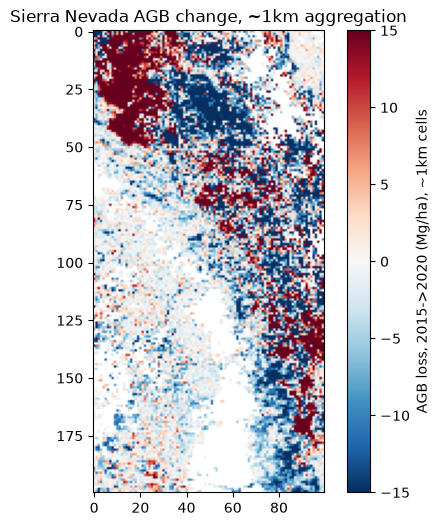

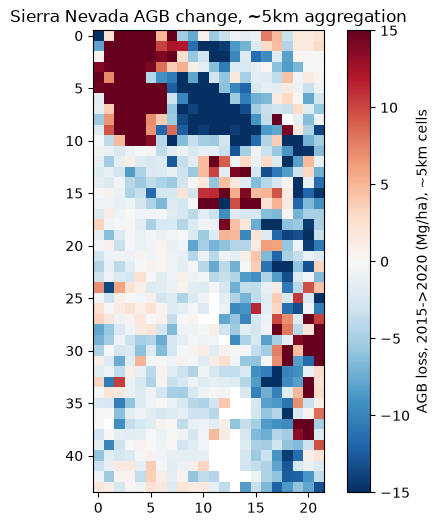

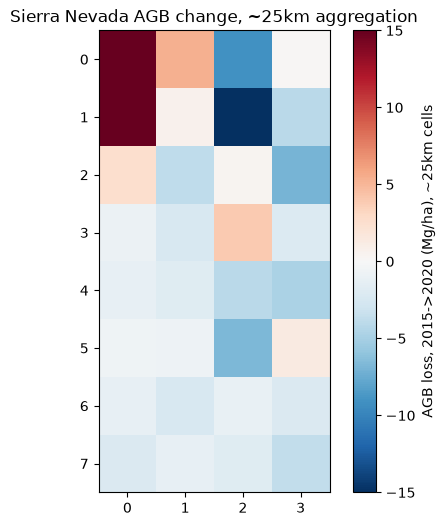

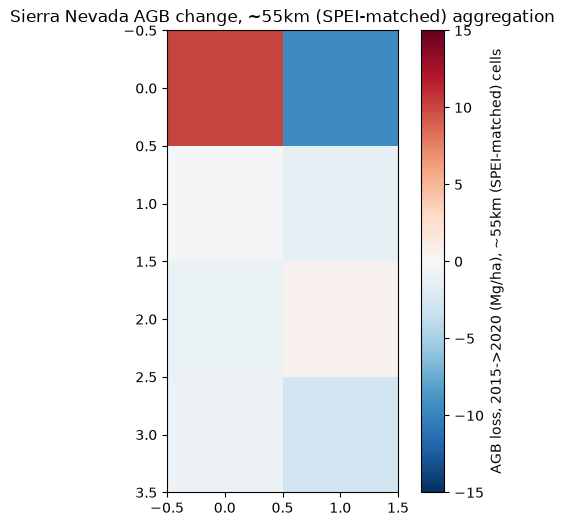

In [14]:
import rasterio
from rasterio.warp import Resampling
from rasterio.transform import from_origin
import numpy as np
import sys
sys.path.insert(0, "../src")
from grids import reproject_to_grid

def aggregate(path, cell_size_deg):
    with rasterio.open(path) as src:
        arr = src.read(1)
        src_transform, src_crs = src.transform, src.crs
        bounds = src.bounds
        nodata = src.nodata

    width = int((bounds.right - bounds.left) / cell_size_deg)
    height = int((bounds.top - bounds.bottom) / cell_size_deg)
    dst_transform = from_origin(bounds.left, bounds.top, cell_size_deg, cell_size_deg)

    out = reproject_to_grid(
        arr, src_transform, src_crs,
        dst_shape=(height, width), dst_transform=dst_transform, dst_crs=src_crs,
        resampling=Resampling.average, src_nodata=nodata,
    )
    return out

cell_sizes_deg = {"~1km": 0.01, "~5km": 0.045, "~25km": 0.225, "~55km (SPEI-matched)": 0.5}

for label, cell_size in cell_sizes_deg.items():
    agb_2015_agg = aggregate("../data/raw/agb/agb_2015.tif", cell_size)
    agb_2020_agg = aggregate("../data/raw/agb/agb_2020.tif", cell_size)
    loss_agg = agb_2015_agg - agb_2020_agg

    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(loss_agg, cmap="RdBu_r", vmin=-15, vmax=15)
    plt.colorbar(im, label=f"AGB loss, 2015->2020 (Mg/ha), {label} cells")
    plt.title(f"Sierra Nevada AGB change, {label} aggregation")
    plt.savefig(f"../data/raw/agb_loss_map_2015_2020_{label.replace('~','').replace(' ','_')}.png", dpi=150)
    plt.show()



In [15]:
import ee
ee.Initialize(project="tree-fire-510209")

sierra_bbox = ee.Geometry.Rectangle([-119.5, 35.5, -118.5, 37.5])
srtm = ee.Image("USGS/SRTMGL1_003")
terrain = ee.Terrain.products(srtm)  # adds 'slope', 'aspect' bands
terrain_clip = terrain.select(["slope", "aspect"]).clip(sierra_bbox)

url = terrain_clip.getDownloadURL({"scale": 100, "region": sierra_bbox, "format": "GEO_TIFF"})
print(url)


https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/e9a5a8889c52e99e871af17fac3d85b6-2f40599818e6e0d88d44be3830e73144:getPixels


correlation, loss vs slope: 0.003516729472090374


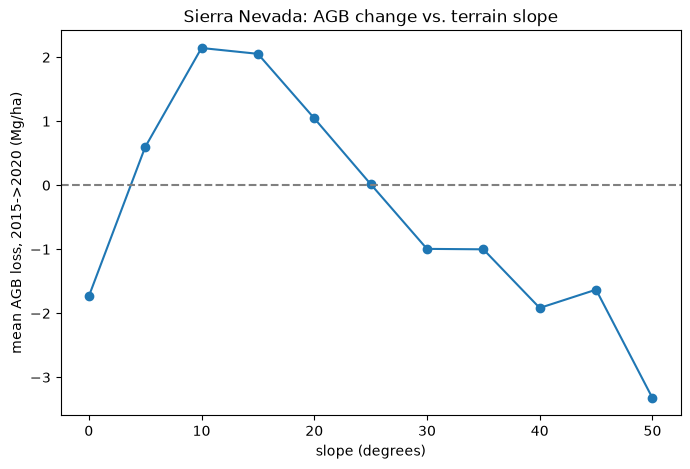

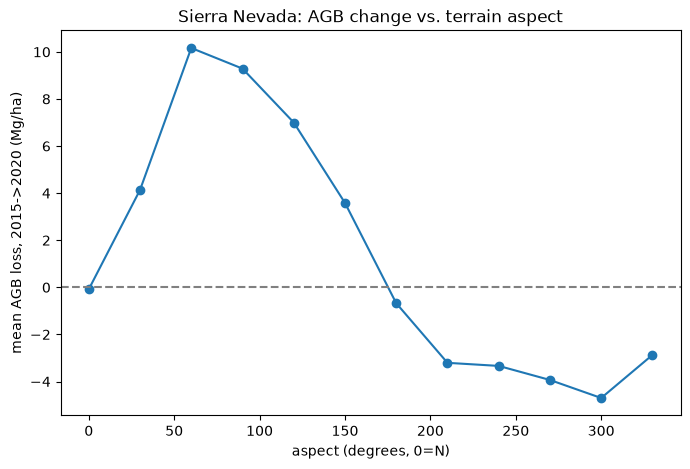

In [16]:
with rasterio.open("../data/raw/srtm_slope_aspect.tif") as src:
    slope = src.read(1)
    aspect = src.read(2)

with rasterio.open("../data/raw/agb/agb_2015.tif") as src:
    agb_2015 = src.read(1, masked=True).astype("float32").filled(np.nan)
with rasterio.open("../data/raw/agb/agb_2020.tif") as src:
    agb_2020 = src.read(1, masked=True).astype("float32").filled(np.nan)

loss = agb_2015 - agb_2020
valid = ~np.isnan(loss) & ~np.isnan(slope)

print("correlation, loss vs slope:", np.corrcoef(loss[valid], slope[valid])[0, 1])

# bin by slope, look at mean loss per bin - a shape plot, not just one number
bins = np.arange(0, 60, 5)
bin_idx = np.digitize(slope[valid], bins)
bin_means = [loss[valid][bin_idx == i].mean() for i in range(1, len(bins))]
plt.figure(figsize=(8, 5))
plt.plot(bins[:-1], bin_means, marker="o")
plt.xlabel("slope (degrees)")
plt.ylabel("mean AGB loss, 2015->2020 (Mg/ha)")
plt.title("Sierra Nevada: AGB change vs. terrain slope")
plt.axhline(0, color="gray", linestyle="--")
plt.savefig("../data/raw/loss_vs_slope.png", dpi=150)
plt.show()

# same for aspect (direction-dependent if it's a look-angle/layover effect)
aspect_bins = np.arange(0, 361, 30)
aspect_idx = np.digitize(aspect[valid], aspect_bins)
aspect_means = [loss[valid][aspect_idx == i].mean() for i in range(1, len(aspect_bins))]
plt.figure(figsize=(8, 5))
plt.plot(aspect_bins[:-1], aspect_means, marker="o")
plt.xlabel("aspect (degrees, 0=N)")
plt.ylabel("mean AGB loss, 2015->2020 (Mg/ha)")
plt.title("Sierra Nevada: AGB change vs. terrain aspect")
plt.axhline(0, color="gray", linestyle="--")
plt.savefig("../data/raw/loss_vs_aspect.png", dpi=150)
plt.show()


fraction of bbox kept (slope < 12 deg): 0.4065660404022312


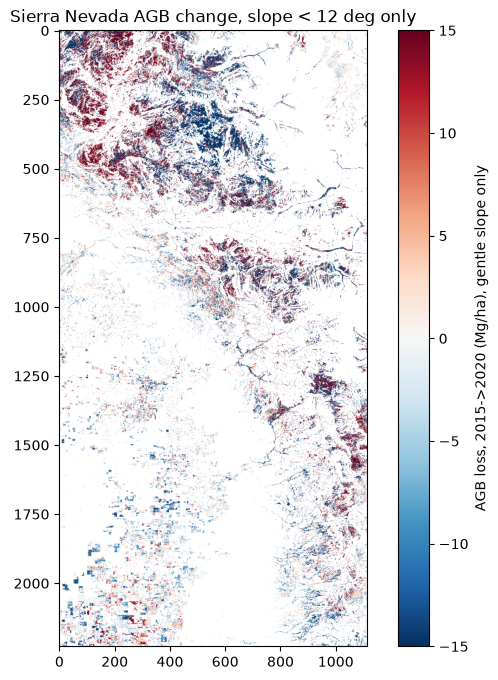

In [17]:
with rasterio.open("../data/raw/srtm_slope_aspect.tif") as src:
    slope = src.read(1)

gentle = slope < 12
loss_gentle = np.where(gentle, loss, np.nan)

print("fraction of bbox kept (slope < 12 deg):", gentle[valid].mean())

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(loss_gentle, cmap="RdBu_r", vmin=-15, vmax=15)
plt.colorbar(im, label="AGB loss, 2015->2020 (Mg/ha), gentle slope only")
plt.title("Sierra Nevada AGB change, slope < 12 deg only")
plt.savefig("../data/raw/agb_loss_gentle_slope.png", dpi=150)
plt.show()
